# Phase 29 — Manuscript figure: decision curves with bootstrap intervals (Study 2)
**Resolves:** R2-8 (net benefit with uncertainty). Reads `S2_dca_curves.csv` written by Phase 21 and draws, for each analysis, the random-forest
net benefit with its 95% bootstrap band, treat-all and treat-none, and a marker row showing thresholds where the lower bound of both the model's
net benefit and of its difference from treat-all exceeds zero ("robust").
**Output:** `reports/figures/revision/S2_decision_curves_with_CI.png` (upload to Overleaf as `S2_decision_curves_with_CI.png`).

In [1]:
import os, sys, json, warnings
import numpy as np
import pandas as pd
warnings.filterwarnings("ignore")
sys.path.append(os.path.abspath(os.path.join(os.getcwd(), "..", "src")))
from revision_utils import *

ENV = get_env()          # paths + config (notebooks must be run from the notebooks/ folder)
SEED = ENV["SEED"]       # 42
B = ENV["N_BOOT"]        # 2000 bootstrap resamples (config.yaml)
print("Project root:", ENV["ROOT"], "| outputs ->", ENV["REV"])

Project root: C:\maternal-mental-health-risk | outputs -> C:\maternal-mental-health-risk\reports/tables\revision


Saved figure: C:\maternal-mental-health-risk\reports\figures\revision\S2_decision_curves_with_CI.png


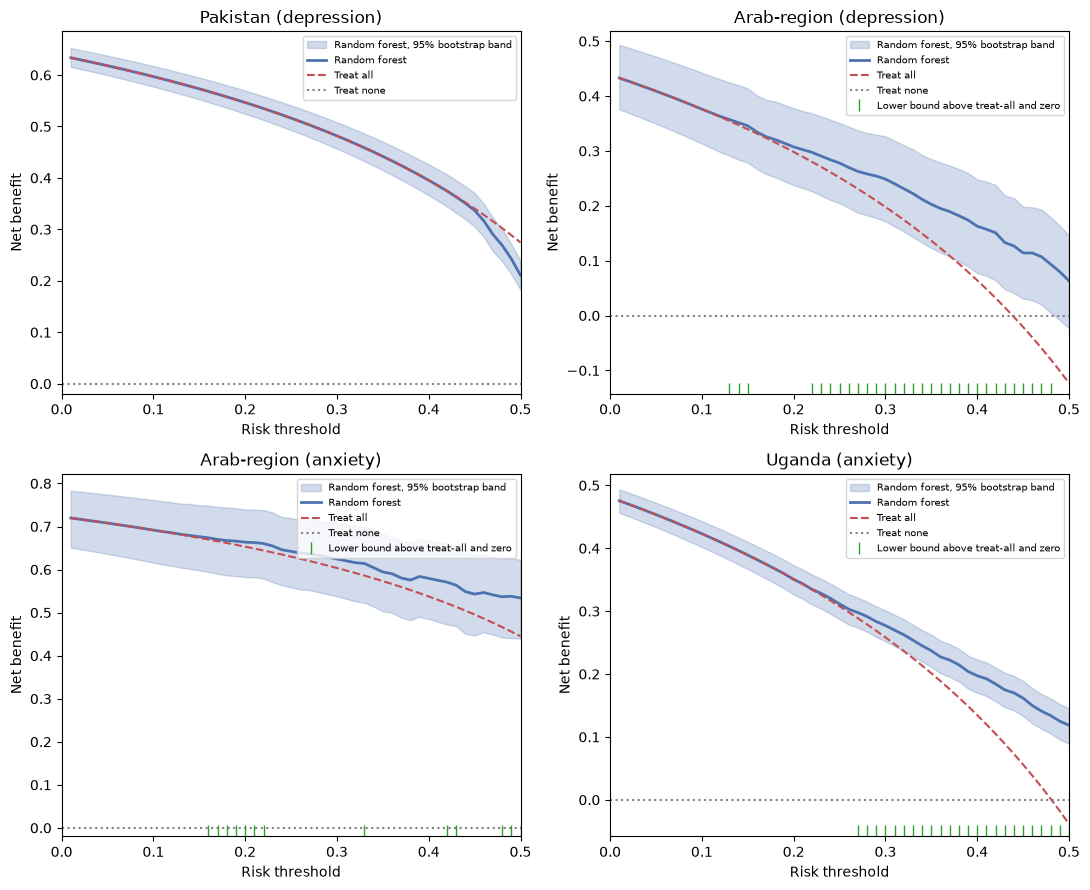

In [2]:
import matplotlib; import matplotlib.pyplot as plt
from plotting_utils import save_fig
d = pd.read_csv(os.path.join(ENV["REV"], "S2_dca_curves.csv"))
fig, axes = plt.subplots(2, 2, figsize=(11, 9)); axes = axes.ravel()
for ax, (tag, info) in zip(axes, DATASETS.items()):
    g = d[d.dataset == tag]
    lo = max(-0.25, float(min(g.nb_treat_all.min(), g.nb_model_ci_lower.min(), 0.0)) - 0.02)
    hi = float(max(g.nb_model_ci_upper.max(), g.nb_treat_all.max())) * 1.05
    ax.fill_between(g.threshold, g.nb_model_ci_lower, g.nb_model_ci_upper, color="#4C72B0", alpha=0.25, label="Random forest, 95% bootstrap band")
    ax.plot(g.threshold, g.nb_model, color="#4C72B0", lw=2, label="Random forest")
    ax.plot(g.threshold, g.nb_treat_all, "--", color="#C44E52", label="Treat all")
    ax.axhline(0, ls=":", color="grey", label="Treat none")
    rb = g[g.robust_beats_both]
    if len(rb):
        ax.plot(rb.threshold, np.full(len(rb), lo + 0.015 * (hi - lo)), "|", color="#2ca02c", ms=9, label="Lower bound above treat-all and zero")
    ax.set_ylim(lo, hi); ax.set_xlim(0, 0.5)
    ax.set_xlabel("Risk threshold"); ax.set_ylabel("Net benefit"); ax.set_title(info["pretty"]); ax.legend(fontsize=7, loc="upper right")
plt.tight_layout(); save_fig(fig, "S2_decision_curves_with_CI.png", ENV["ROOT"], dataset="revision"); plt.show()